In [18]:
# Mengimpor library yang dibutuhkan

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

print("Library berhasil diimpor!")

Library berhasil diimpor!


In [19]:
# Membuat koneksi database
conn = sqlite3.connect('perpustakaan.db')

# Membuat cursor
cursor = conn.cursor()

# Mengaktifkan foreign key
cursor.execute("PRAGMA foreign_keys = ON;")

print("Database perpustakaan berhasil dibuat!")

Database perpustakaan berhasil dibuat!


In [20]:
# Menghapus tabel lama jika notebook dijalankan ulang
cursor.execute("DROP TABLE IF EXISTS peminjaman")
cursor.execute("DROP TABLE IF EXISTS anggota")
cursor.execute("DROP TABLE IF EXISTS buku")

# Membuat tabel buku
cursor.execute("""
CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
)
""")

# Membuat tabel anggota
cursor.execute("""
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE
)
""")

# Membuat tabel peminjaman
cursor.execute("""
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
""")

conn.commit()

print("Tabel buku, anggota, dan peminjaman berhasil dibuat!")

Tabel buku, anggota, dan peminjaman berhasil dibuat!


In [21]:
# Data buku
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi', 'Tere Liye', 2014),
    ('Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    ('Atomic Habits', 'James Clear', 2018),
    ('Laut Bercerita', 'Leila S. Chudori', 2017)
]

cursor.executemany("""
INSERT INTO buku (judul, penulis, tahun)
VALUES (?, ?, ?)
""", data_buku)

conn.commit()

print("5 data buku berhasil ditambahkan!")

5 data buku berhasil ditambahkan!


In [22]:
# Data anggota
data_anggota = [
    ('Muhammad Sofil', 'sofil@gmail.com'),
    ('Saefurrohman', 'saeful@gmail.com'),
    ('Jeffry', 'jeffry@gmail.com')
]

cursor.executemany("""
INSERT INTO anggota (nama, email)
VALUES (?, ?)
""", data_anggota)

conn.commit()

print("3 data anggota berhasil ditambahkan!")

3 data anggota berhasil ditambahkan!


In [23]:
# Data transaksi peminjaman
data_peminjaman = [
    (1, 1, '2025-01-05', '2025-01-12'),
    (2, 2, '2025-01-07', '2025-01-17'),
    (1, 3, '2025-01-15', None),
    (3, 4, '2025-01-20', '2025-01-25')
]

cursor.executemany("""
INSERT INTO peminjaman
(id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?)
""", data_peminjaman)

conn.commit()

print("4 transaksi peminjaman berhasil ditambahkan!")

4 transaksi peminjaman berhasil ditambahkan!


In [24]:
query_join = """
SELECT
    p.id AS ID,
    a.nama AS Nama_Anggota,
    b.judul AS Judul_Buku,
    p.tgl_pinjam AS Tanggal_Pinjam,
    p.tgl_kembali AS Tanggal_Kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_join, conn)

# Mengubah format tanggal
for kolom in ['Tanggal_Pinjam', 'Tanggal_Kembali']:
    df_peminjaman[kolom] = pd.to_datetime(
        df_peminjaman[kolom]
    ).dt.strftime('%d-%m-%Y').fillna('Belum kembali')

display(df_peminjaman)

,ID,Nama_Anggota,Judul_Buku,Tanggal_Pinjam,Tanggal_Kembali
0,1,Muhammad Sofil,Laskar Pelangi,05-01-2025,12-01-2025
1,2,Saefurrohman,Bumi,07-01-2025,17-01-2025
2,3,Muhammad Sofil,Negeri 5 Menara,15-01-2025,Belum kembali
3,4,Jeffry,Atomic Habits,20-01-2025,25-01-2025


In [25]:
query_anggota = """
SELECT
    a.nama AS Nama_Anggota,
    COUNT(p.id) AS Jumlah_Peminjaman
FROM anggota a
LEFT JOIN peminjaman p
    ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY Jumlah_Peminjaman DESC;
"""

df_jumlah = pd.read_sql_query(query_anggota, conn)

display(df_jumlah)

,Nama_Anggota,Jumlah_Peminjaman
0,Muhammad Sofil,2
1,Saefurrohman,1
2,Jeffry,1


In [26]:
# Membuat ringkasan data peminjaman
ringkasan = pd.DataFrame({
    'Keterangan': [
        'Total Transaksi',
        'Jumlah Anggota',
        'Jumlah Buku Dipinjam',
        'Sudah Dikembalikan',
        'Belum Dikembalikan'
    ],
    'Jumlah': [
        len(df_peminjaman),
        df_peminjaman['Nama_Anggota'].nunique(),
        df_peminjaman['Judul_Buku'].nunique(),
        df_peminjaman['Tanggal_Kembali'].ne('Belum kembali').sum(),
        df_peminjaman['Tanggal_Kembali'].eq('Belum kembali').sum()
    ]
})

display(ringkasan)

,Keterangan,Jumlah
0,Total Transaksi,4
1,Jumlah Anggota,3
2,Jumlah Buku Dipinjam,4
3,Sudah Dikembalikan,3
4,Belum Dikembalikan,1


In [27]:
# Membuat salinan data untuk analisis
df_analisis = pd.read_sql_query(query_join, conn)

# Mengubah kolom tanggal
df_analisis['tgl_pinjam'] = pd.to_datetime(
    df_analisis['Tanggal_Pinjam']
)

df_analisis['tgl_kembali'] = pd.to_datetime(
    df_analisis['Tanggal_Kembali']
)

# Menghitung durasi peminjaman
df_analisis['Durasi_Peminjaman'] = (
    df_analisis['tgl_kembali'] -
    df_analisis['tgl_pinjam']
).dt.days

# Menyiapkan tabel hasil
hasil_durasi = df_analisis[[
    'Nama_Anggota',
    'Judul_Buku',
    'Durasi_Peminjaman'
]].copy()

hasil_durasi['Durasi_Peminjaman'] = (
    hasil_durasi['Durasi_Peminjaman']
    .apply(
        lambda x: f'{int(x)} hari'
        if pd.notna(x)
        else 'Belum dikembalikan'
    )
)

hasil_durasi.columns = [
    'Nama Anggota',
    'Judul Buku',
    'Durasi Peminjaman'
]

display(hasil_durasi)

,Nama Anggota,Judul Buku,Durasi Peminjaman
0,Muhammad Sofil,Laskar Pelangi,7 hari
1,Saefurrohman,Bumi,10 hari
2,Muhammad Sofil,Negeri 5 Menara,Belum dikembalikan
3,Jeffry,Atomic Habits,5 hari


In [28]:
# Menghitung rata-rata durasi peminjaman
rata_rata = df_analisis['Durasi_Peminjaman'].mean()

print("HASIL ANALISIS PEMINJAMAN")
print("=========================")
print("Total transaksi       :", len(df_analisis))
print("Buku sudah dikembalikan:", df_analisis['tgl_kembali'].notna().sum())
print("Buku belum dikembalikan:", df_analisis['tgl_kembali'].isna().sum())
print(f"Rata-rata durasi      : {rata_rata:.2f} hari")

HASIL ANALISIS PEMINJAMAN
Total transaksi       : 4
Buku sudah dikembalikan: 3
Buku belum dikembalikan: 1
Rata-rata durasi      : 7.33 hari


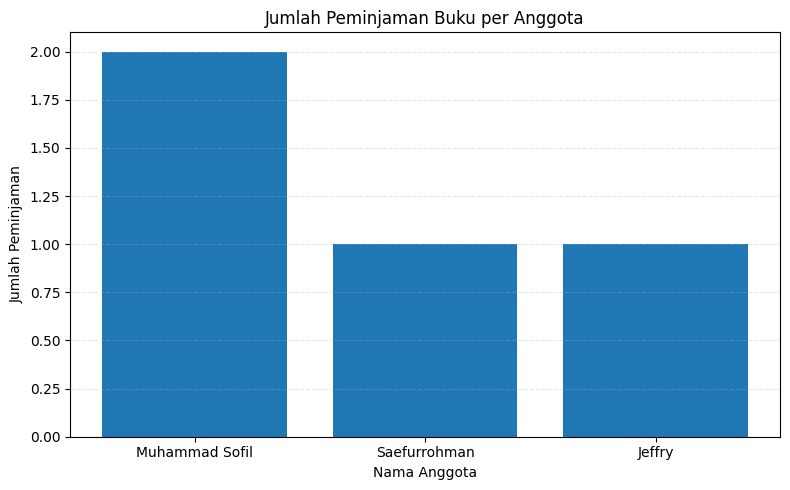

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_jumlah['Nama_Anggota'],
    df_jumlah['Jumlah_Peminjaman']
)

plt.title('Jumlah Peminjaman Buku per Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Peminjaman')

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

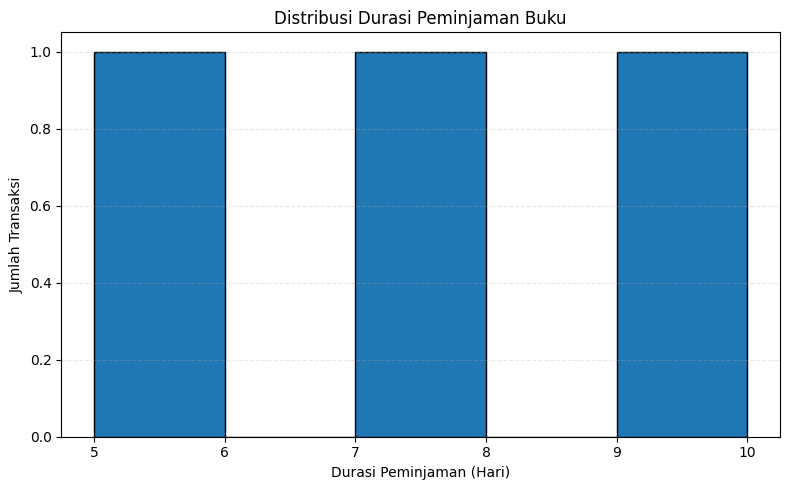

In [30]:
# Mengambil data durasi yang valid
durasi = df_analisis['Durasi_Peminjaman'].dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    durasi,
    bins=5,
    edgecolor='black'
)

plt.title('Distribusi Durasi Peminjaman Buku')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.ylabel('Jumlah Transaksi')

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()